# Conditional GAN untuk Fashion-MNIST (PyTorch, dari nol)

Notebook tunggal untuk proyek kelompok: membangun *Conditional GAN* di atas Fashion-MNIST tanpa menyalin tutorial atau repo orang lain. Semua angka (ukuran tensor, hyperparameter) mengikuti **cetak biru** yang sudah disepakati.

**Daftar bagian**

| Bagian | Isi | Status |
| --- | --- | --- |
| 0 | Setup & Config | ada di notebook ini |
| 1 | Utils: weight init, simpan grid gambar, simpan/muat checkpoint | ada di notebook ini |
| 2 | Generator | ada di notebook ini |

Bagian berikutnya ditambahkan di bawah Bagian 2 dengan pola yang sama.

**Aturan notebook**

1. Jalankan dari atas ke bawah (`Runtime > Run all`). Pilih GPU dulu: `Runtime > Change runtime type > T4 GPU`.
2. Antar-bagian hanya berbagi variabel dari Bagian 0 (`CFG`, `DEVICE`, `CLASS_NAMES`) dan fungsi helper dari Bagian 1. Semua hyperparameter hanya diubah di satu tempat: cell config di Bagian 0.
3. Setiap cell aman dijalankan ulang.
4. Pola tiap bagian: **Konsep** (markdown) → **Kode** (dengan komentar alasan) → **Tes** (cell kode berisi `assert`).

# Bagian 0: Setup & Config

## Konsep: untuk apa bagian ini?

Bagian 0 menyiapkan tiga hal yang dipakai semua bagian lain:

1. **Import terpusat.** Semua dependensi proyek terlihat di satu cell.
2. **Seed dan device.** `set_seed` mengunci keacakan supaya eksperimen bisa diulang dan dibandingkan (penting saat membandingkan baseline dengan dropout atau spectral norm). `DEVICE` memilih GPU bila ada.
3. **Config.** Satu `dataclass` bernama `Config` berisi semua hyperparameter dan ukuran. Kalau angka tersebar di banyak cell, tim sulit melacak "run mana memakai nilai apa" dan log eksperimen menjadi rancu. Dengan satu sumber kebenaran, mengubah `lr_d` cukup di satu baris.

`dataclass` dipilih dibanding `dict` karena nilai diakses sebagai `CFG.z_dim`: typo langsung menjadi error (bukan diam-diam menghasilkan `None`), nilai turunan bisa dihitung dengan `@property`, dan seluruh isinya mudah diubah menjadi dict untuk disimpan di checkpoint.

### 0.1 Import dan versi library

Semua `import` dikumpulkan di sini. Versi library dicetak supaya log dokumentasi mencatat lingkungan yang dipakai.

In [1]:
# Semua import dikumpulkan di satu tempat: cell lain tidak perlu mengimpor ulang,
# dan siapa pun bisa melihat seluruh dependensi proyek sekilas.
import os
import sys
import json
import random
import tempfile
from dataclasses import dataclass, asdict
from typing import Tuple

import numpy as np
import torch
import torch.nn as nn
import torchvision
import matplotlib.pyplot as plt
from PIL import Image
from torchvision.utils import make_grid, save_image

print("Python      :", sys.version.split()[0])
print("PyTorch     :", torch.__version__)
print("Torchvision :", torchvision.__version__)

Python      : 3.13.16
PyTorch     : 2.11.0+cu130
Torchvision : 0.26.0+cu130


### 0.2 Seed dan device

- `set_seed` mengunci lima sumber keacakan: `random` Python, NumPy, PyTorch CPU, PyTorch GPU, dan perilaku cuDNN.
- `cudnn.deterministic=True` memaksa algoritma konvolusi yang hasilnya sama antar-run, dan `benchmark=False` mematikan auto-tuner yang bisa memilih algoritma berbeda tiap run. Harganya sedikit lebih lambat, wajar untuk eksperimen yang harus bisa diulang.
- Catatan jujur: beberapa operasi GPU masih bisa berbeda di digit terakhir, jadi "reproducible" berarti hasilnya sangat mirip, bukan dijamin identik per bit.
- Jika notebook berjalan di CPU, training akan jauh lebih lambat. Cell ini memberi peringatan agar tim sadar sebelum membuang waktu.

In [2]:
def set_seed(seed: int) -> None:
    """Mengunci semua sumber keacakan supaya hasil eksperimen bisa diulang."""
    random.seed(seed)                  # random bawaan Python
    np.random.seed(seed)               # NumPy
    torch.manual_seed(seed)            # PyTorch (CPU)
    torch.cuda.manual_seed_all(seed)   # PyTorch (semua GPU); aman dipanggil walau tanpa GPU
    # deterministic=True: konvolusi memakai algoritma yang hasilnya konsisten antar-run.
    # benchmark=False : tidak ada auto-tuner yang bisa memilih algoritma berbeda tiap run.
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


# Pilih GPU jika ada. Tensor dan model harus berada di device yang sama,
# jadi seluruh notebook memakai satu variabel DEVICE ini.
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", DEVICE)
if DEVICE.type == "cuda":
    print("GPU   :", torch.cuda.get_device_name(0))
else:
    print("PERINGATAN: berjalan di CPU. Aktifkan GPU lewat Runtime > Change runtime type > T4 GPU.")

Device: cuda
GPU   : Tesla T4


### 0.3 Config: satu sumber kebenaran

Config dikelompokkan sesuai bagian cetak biru:

- **Data**: ukuran gambar, normalisasi, batch size.
- **Model**: dimensi noise `z_dim`, dimensi embedding label, jumlah channel tiap layer G dan D.
- **Training**: learning rate, betas, jumlah epoch, target label smoothing.
- **Evaluasi & logging**: frekuensi simpan grid dan checkpoint.
- **Path**: lokasi keluaran (diisi otomatis di Bagian 1).

Beberapa poin penting:

- `d_dropout=0.0` dan `d_spectral_norm=False` adalah **saklar cadangan** dari cetak biru bagian 6. Nilai default membuat keduanya mati; baru dinyalakan bila grafik menunjukkan masalah.
- Nilai turunan memakai `@property` supaya tidak bisa tidak sinkron dengan nilai induknya: `d_embed_dim` = 28×28 = 784, `iters_per_epoch` = 60.000 // 128 = 468 (karena `drop_last=True`), `g_init_size` = 28 // 4 = 7.
- `__post_init__` memvalidasi nilai saat `Config()` dibuat. Lebih baik gagal di sini dengan pesan jelas daripada gagal 20 menit kemudian di tengah training.
- Config tidak dibekukan (`frozen`) karena Bagian 1 perlu mengisi path keluaran. Aturan tim: **jangan mengubah `CFG` di luar cell ini**, kecuali oleh `setup_output_dirs`.

In [3]:
CLASS_NAMES = ("T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
               "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot")


@dataclass
class Config:
    # ---------- Reproducibility ----------
    seed: int = 42

    # ---------- Data ----------
    data_dir: str = "./data"
    img_size: int = 28               # Fashion-MNIST: 28x28
    img_channels: int = 1            # grayscale
    num_classes: int = 10
    norm_mean: float = 0.5           # Normalize((0.5,), (0.5,)) -> rentang [-1, 1], cocok dengan Tanh di G
    norm_std: float = 0.5
    batch_size: int = 128
    num_workers: int = 2             # Colab hanya punya 2 CPU
    train_size: int = 60_000         # ukuran split train FashionMNIST

    # ---------- Model ----------
    z_dim: int = 100                 # dimensi noise
    g_embed_dim: int = 50            # dimensi embedding label di G
    g_channels: Tuple[int, int, int] = (128, 64, 32)    # channel layer G: 7x7 -> 14x14 -> 28x28
    d_channels: Tuple[int, int, int] = (64, 128, 256)   # channel layer konvolusi D
    leaky_slope: float = 0.2         # kemiringan LeakyReLU di D
    init_std: float = 0.02           # std inisialisasi bobot N(0, 0.02)
    d_dropout: float = 0.0           # CADANGAN 1 (bagian 6): 0.0 = mati, 0.3 = dropout dinyalakan
    d_spectral_norm: bool = False    # CADANGAN 2 (bagian 6): True = spectral norm di D (tanpa BatchNorm)

    # ---------- Training ----------
    epochs: int = 50
    lr_g: float = 2e-4
    lr_d: float = 2e-4
    beta1: float = 0.5               # momentum Adam rendah: cepat menyesuaikan diri terhadap lawan
    beta2: float = 0.999
    weight_decay: float = 0.0
    d_steps: int = 1                 # rasio update 1 : 1
    g_steps: int = 1                 # naikkan ke 2 hanya bila D terlalu kuat (bagian 9)
    real_target: float = 0.9         # one-sided label smoothing: target real 0.9
    fake_target: float = 0.0         # target fake tetap 0.0
    g_target: float = 1.0            # G ingin D menilai fake sebagai real (target 1.0, tanpa smoothing)

    # ---------- Evaluasi & logging ----------
    sample_every: int = 5            # simpan grid sampel tiap 5 epoch
    ckpt_every: int = 10             # simpan checkpoint tiap 10 epoch
    n_per_class_grid: int = 10       # grid: 10 baris (kelas) x 10 kolom (sampel)
    eval_per_class: int = 1000       # jumlah gambar buatan per kelas untuk classifier pendamping

    # ---------- Path keluaran (diisi oleh setup_output_dirs di Bagian 1) ----------
    use_drive: bool = True
    drive_root: str = "/content/drive/MyDrive/cgan_fashion_mnist"
    local_root: str = "./outputs"
    out_root: str = ""
    ckpt_dir: str = ""
    sample_dir: str = ""
    log_dir: str = ""

    # ---------- Nilai turunan (tidak disimpan, selalu konsisten dengan nilai induknya) ----------
    @property
    def d_embed_dim(self) -> int:
        return self.img_size * self.img_size        # 784: label di D dibentuk jadi peta 1x28x28

    @property
    def iters_per_epoch(self) -> int:
        return self.train_size // self.batch_size   # 468, karena drop_last=True

    @property
    def g_init_size(self) -> int:
        return self.img_size // 4                   # 7: G menggandakan resolusi dua kali (7->14->28)

    def __post_init__(self):
        # Validasi dini: gagal cepat dengan pesan jelas.
        if self.img_size % 4 != 0:
            raise ValueError("img_size harus kelipatan 4 (G menggandakan resolusi dua kali).")
        if self.batch_size <= 0 or self.epochs <= 0:
            raise ValueError("batch_size dan epochs harus > 0.")
        if self.sample_every <= 0 or self.ckpt_every <= 0:
            raise ValueError("sample_every dan ckpt_every harus > 0.")
        if not (0.0 <= self.d_dropout < 1.0):
            raise ValueError("d_dropout harus di rentang [0, 1).")
        if len(CLASS_NAMES) != self.num_classes:
            raise ValueError("Jumlah CLASS_NAMES harus sama dengan num_classes.")


CFG = Config()
set_seed(CFG.seed)   # kunci seed segera setelah config dibuat

print(json.dumps(asdict(CFG), indent=2))
print("\nNilai turunan:")
print("  d_embed_dim     =", CFG.d_embed_dim)
print("  iters_per_epoch =", CFG.iters_per_epoch)
print("  g_init_size     =", CFG.g_init_size)

{
  "seed": 42,
  "data_dir": "./data",
  "img_size": 28,
  "img_channels": 1,
  "num_classes": 10,
  "norm_mean": 0.5,
  "norm_std": 0.5,
  "batch_size": 128,
  "num_workers": 2,
  "train_size": 60000,
  "z_dim": 100,
  "g_embed_dim": 50,
  "g_channels": [
    128,
    64,
    32
  ],
  "d_channels": [
    64,
    128,
    256
  ],
  "leaky_slope": 0.2,
  "init_std": 0.02,
  "d_dropout": 0.0,
  "d_spectral_norm": false,
  "epochs": 50,
  "lr_g": 0.0002,
  "lr_d": 0.0002,
  "beta1": 0.5,
  "beta2": 0.999,
  "weight_decay": 0.0,
  "d_steps": 1,
  "g_steps": 1,
  "real_target": 0.9,
  "fake_target": 0.0,
  "g_target": 1.0,
  "sample_every": 5,
  "ckpt_every": 10,
  "n_per_class_grid": 10,
  "eval_per_class": 1000,
  "use_drive": true,
  "drive_root": "/content/drive/MyDrive/cgan_fashion_mnist",
  "local_root": "./outputs",
  "out_root": "",
  "ckpt_dir": "",
  "sample_dir": "",
  "log_dir": ""
}

Nilai turunan:
  d_embed_dim     = 784
  iters_per_epoch = 468
  g_init_size     = 7


### Tes 0: cara memeriksa Bagian 0

Cell di bawah memeriksa empat hal:

1. Nilai config sama dengan cetak biru (jika ada yang diubah tanpa sengaja, pesan error menyebut nama dan nilainya).
2. Seed bekerja: dua kali `set_seed(123)` menghasilkan angka acak yang sama.
3. `DEVICE` bisa menerima tensor.
4. Config yang salah ditolak (`batch_size=0` harus memunculkan `ValueError`).

**Hasil yang diharapkan:** tercetak `TES BAGIAN 0 LULUS`. Jika muncul `AssertionError`, baca pesannya: ia menyebut nilai mana yang tidak sesuai.

In [4]:
# --- Tes 0.1: nilai config harus sama dengan cetak biru ---
expected = dict(seed=42, img_size=28, batch_size=128, z_dim=100, g_embed_dim=50,
                epochs=50, lr_g=2e-4, lr_d=2e-4, beta1=0.5, beta2=0.999,
                real_target=0.9, fake_target=0.0)
for name, value in expected.items():
    assert getattr(CFG, name) == value, f"CFG.{name} = {getattr(CFG, name)}, seharusnya {value}"
assert CFG.d_embed_dim == 784, CFG.d_embed_dim
assert CFG.iters_per_epoch == 468, CFG.iters_per_epoch
assert CFG.g_init_size == 7, CFG.g_init_size
assert CFG.g_channels == (128, 64, 32) and CFG.d_channels == (64, 128, 256)
assert CFG.d_dropout == 0.0 and CFG.d_spectral_norm is False, "saklar cadangan harus mati di baseline"

# --- Tes 0.2: seed membuat angka acak berulang ---
set_seed(123); a = torch.randn(5)
set_seed(123); b = torch.randn(5)
assert torch.equal(a, b), "set_seed tidak membuat hasil berulang"
set_seed(CFG.seed)   # kembalikan ke seed proyek

# --- Tes 0.3: DEVICE bisa dipakai ---
x = torch.zeros(2, device=DEVICE)
assert x.device.type == DEVICE.type

# --- Tes 0.4: config yang salah harus ditolak ---
try:
    Config(batch_size=0)
except ValueError:
    pass
else:
    raise AssertionError("Config(batch_size=0) seharusnya memunculkan ValueError")

print("TES BAGIAN 0 LULUS")

TES BAGIAN 0 LULUS


# Bagian 1: Utils

## Konsep: untuk apa bagian ini?

Bagian 1 berisi alat bantu kecil yang dipakai berulang oleh Generator, Discriminator, training loop, dan evaluasi. Dipisah di awal supaya bagian lain tidak perlu menulis ulang dan, yang lebih penting, supaya perilakunya **seragam**: semua orang menyimpan gambar dengan cara yang sama dan memuat checkpoint dengan cara yang sama.

Isi bagian ini:

| Sub-bagian | Fungsi | Dipakai oleh |
| --- | --- | --- |
| 1.1 | `weights_init` | G dan D |
| 1.2 | `denormalize`, `make_fixed_noise`, `save_image_grid`, `show_image_grid` | training loop, evaluasi, generate |
| 1.3 | `setup_output_dirs` (folder keluaran + Google Drive) | training loop, evaluasi |
| 1.4 | `ckpt_path`, `save_checkpoint`, `load_checkpoint`, `latest_checkpoint` | training loop, generate |

### 1.1 Weight init

Bobot awal menentukan apakah training GAN mulai tenang atau langsung bermasalah. Aturan dari cetak biru:

| Layer | Weight | Bias |
| --- | --- | --- |
| `Conv2d`, `ConvTranspose2d`, `Linear` | N(0; 0,02) | 0 |
| `BatchNorm` | N(1; 0,02) | 0 |
| `Embedding` | tidak diubah (default PyTorch, N(0; 1)) | tidak ada |

- **Kenapa kecil (std 0,02)?** Aktivasi awal kecil, sehingga D belum bisa "terlalu yakin" di iterasi pertama dan gradien ke G tidak mati sejak awal. Nilai ini adalah konvensi umum untuk GAN konvolusional.
- **Kenapa BatchNorm weight dekat 1?** Weight BatchNorm adalah skala keluaran normalisasi. Dimulai di sekitar 1 membuat normalisasi awalnya hampir tidak mengubah skala, dengan sedikit variasi acak.
- **Cara pakai:** `model.apply(weights_init)`. `apply` memanggil fungsi pada **setiap** sub-modul secara rekursif, jadi satu fungsi cukup untuk seluruh jaringan.
- **Peringatan untuk nanti:** jika spectral norm di D dinyalakan, panggil `apply(weights_init)` **sebelum** layer dibungkus `spectral_norm`, karena pembungkus itu menyimpan bobot asli sebagai `weight_orig`.

In [5]:
def weights_init(module: nn.Module) -> None:
    """Inisialisasi bobot. Dipakai lewat model.apply(weights_init)."""
    if isinstance(module, (nn.Conv2d, nn.ConvTranspose2d, nn.Linear)):
        # Bobot kecil -> keluaran awal kecil -> D dan G mulai dari titik "netral".
        nn.init.normal_(module.weight, mean=0.0, std=CFG.init_std)
        if module.bias is not None:
            nn.init.zeros_(module.bias)          # tanpa offset awal
    elif isinstance(module, (nn.BatchNorm2d, nn.BatchNorm1d)):
        # Skala BatchNorm dimulai di sekitar 1 agar normalisasi awal hampir netral.
        nn.init.normal_(module.weight, mean=1.0, std=CFG.init_std)
        nn.init.zeros_(module.bias)
    # nn.Embedding sengaja dibiarkan memakai init default PyTorch.

#### Tes 1.1: cara memeriksa weight init

Tes membuat jaringan mini berukuran realistis (ada `Conv2d`, `BatchNorm2d`, `ConvTranspose2d`, `Linear`, dan `Embedding`), memanggil `apply(weights_init)`, lalu memeriksa statistik bobotnya. Jaringan sengaja memakai bias (yang default-nya acak) supaya terbukti bias benar-benar di-nol-kan.

**Hasil yang diharapkan:** `TES 1.1 LULUS`. Jika std bobot tidak mendekati 0,02, berarti fungsi tidak terpanggil pada layer tersebut.

In [6]:
toy = nn.Sequential(
    nn.Conv2d(64, 128, 4, 2, 1),               # punya bias (default acak)
    nn.BatchNorm2d(128),
    nn.ConvTranspose2d(128, 64, 4, 2, 1),
    nn.Linear(4096, 1),
)
emb = nn.Embedding(10, 50)
emb_before = emb.weight.detach().clone()

toy.apply(weights_init)
emb.apply(weights_init)

conv, bn, convT, lin = toy[0], toy[1], toy[2], toy[3]
for layer in (conv, convT, lin):
    n = layer.weight.numel()
    std = layer.weight.std().item()
    # Toleransi mengikuti jumlah bobot (galat sampling): 5 galat baku. Layer kecil -> toleransi lebih longgar,
    # tapi init default PyTorch (std ~0.018 untuk Conv, ~0.009 untuk Linear 4096) tetap terdeteksi salah.
    tol_std = 5 * CFG.init_std / (2 * n) ** 0.5
    tol_mean = 5 * CFG.init_std / n ** 0.5
    assert abs(std - CFG.init_std) < tol_std, f"{layer.__class__.__name__}: std={std:.5f}, seharusnya ~{CFG.init_std}"
    assert abs(layer.weight.mean().item()) < tol_mean, f"{layer.__class__.__name__}: mean bobot harus ~0"
    assert torch.count_nonzero(layer.bias) == 0, f"{layer.__class__.__name__}: bias harus 0"

assert abs(bn.weight.mean().item() - 1.0) < 0.01, "weight BatchNorm harus berpusat di ~1"
assert 0.01 < bn.weight.std().item() < 0.03, "weight BatchNorm harus bervariasi dengan std ~0.02"
assert torch.count_nonzero(bn.bias) == 0, "bias BatchNorm harus 0"
assert torch.equal(emb.weight, emb_before), "Embedding tidak boleh diubah oleh weights_init"

print("TES 1.1 LULUS")

TES 1.1 LULUS


### 1.2 Grid gambar: balik normalisasi, noise tetap, simpan, tampilkan

Empat fungsi kecil dalam satu cell:

- **`denormalize(x)`**: mengubah gambar dari rentang model [-1, 1] ke [0, 1]. Model bekerja di [-1, 1] (karena `Tanh` di G dan `Normalize((0.5,), (0.5,))` di data), sedangkan file PNG dan `matplotlib` mengharapkan [0, 1]. Tanpa langkah ini gambar tampil gelap dan nilai negatif terpotong. Rumusnya adalah kebalikan normalisasi: `x = x_norm * std + mean`. Hasilnya di-`clamp` ke [0, 1] untuk membuang selisih kecil akibat pembulatan.
- **`make_fixed_noise()`**: membuat 100 noise `z` [100, 100] dan 100 label, sekali dan selalu sama. Labelnya `0,0,...,0,1,1,...,1,...,9` (masing-masing 10 kali), sehingga **baris ke-i pada grid = kelas ke-i**. Kontrak tata letak ini dipakai bagian evaluasi dan presentasi. Noise dibuat dengan `torch.Generator` terpisah yang di-seed sendiri, sehingga tidak terpengaruh keacakan lain (shuffle data, dropout) dan **identik di setiap run dan setelah resume**. Karena noise tetap, perbedaan grid antar-epoch murni akibat G yang belajar.
- **`save_image_grid(images, path)`**: balik normalisasi, susun dengan `make_grid` (10 kolom, padding 2 piksel putih), simpan PNG, lalu kembalikan tensor grid. Menerima tensor di GPU maupun CPU, dan membuat folder tujuan bila belum ada.
- **`show_image_grid(grid, ...)`**: menampilkan grid di notebook, dengan nama kelas di sisi kiri tiap baris (berguna untuk presentasi).

In [7]:
def denormalize(x: torch.Tensor) -> torch.Tensor:
    """[-1, 1] -> [0, 1]. Kebalikan dari Normalize: x = x_norm * std + mean."""
    # clamp: membuang selisih kecil akibat pembulatan agar benar-benar berada di [0, 1].
    return (x * CFG.norm_std + CFG.norm_mean).clamp(0.0, 1.0)


def make_fixed_noise(device=None):
    """Noise dan label tetap untuk grid: baris ke-i = kelas ke-i, 10 sampel per kelas."""
    device = DEVICE if device is None else device
    n = CFG.num_classes * CFG.n_per_class_grid                      # 10 x 10 = 100
    # Generator terpisah: hasil tidak terganggu RNG global (shuffle, dropout, dst.)
    # dan sama persis di setiap run maupun setelah resume.
    gen = torch.Generator().manual_seed(CFG.seed)
    z = torch.randn(n, CFG.z_dim, generator=gen)                    # [100, 100]
    y = torch.arange(CFG.num_classes).repeat_interleave(CFG.n_per_class_grid)   # [100]: 0 x10, 1 x10, ...
    return z.to(device), y.to(device)


def save_image_grid(images: torch.Tensor, path: str, nrow: int = None) -> torch.Tensor:
    """Simpan batch gambar [N, 1, 28, 28] (rentang [-1, 1]) sebagai satu grid PNG."""
    nrow = CFG.n_per_class_grid if nrow is None else nrow
    # detach: lepas dari graph gradien; cpu: make_grid dan PNG bekerja di CPU.
    images = denormalize(images.detach().cpu().float())
    grid = make_grid(images, nrow=nrow, padding=2, pad_value=1.0)   # [3, H, W] (1 kanal otomatis jadi 3)
    os.makedirs(os.path.dirname(path) or ".", exist_ok=True)
    save_image(grid, path)
    return grid


def show_image_grid(grid: torch.Tensor, title: str = None, row_labels=None) -> None:
    """Tampilkan grid di notebook. row_labels: nama tiap baris (mis. CLASS_NAMES)."""
    plt.figure(figsize=(6, 6))
    plt.imshow(grid.permute(1, 2, 0).numpy())      # [3,H,W] -> [H,W,3] untuk matplotlib
    if row_labels is not None:
        pad = 2
        cell = CFG.img_size + pad
        ys = [pad + i * cell + CFG.img_size / 2 for i in range(len(row_labels))]
        plt.yticks(ys, row_labels, fontsize=8)     # nama kelas di tengah tiap baris
        plt.xticks([])
    else:
        plt.axis("off")
    if title:
        plt.title(title)
    plt.show()

#### Tes 1.2: cara memeriksa grid

Tes ini memeriksa:

1. `denormalize`: -1 → 0, 0 → 0,5, 1 → 1, dan nilai di luar rentang terpotong; plus uji bolak-balik dengan `Normalize`.
2. `make_fixed_noise`: bentuk [100, 100] dan [100], label tersusun per kelas, hasil identik di setiap pemanggilan, dan tidak terpengaruh `set_seed` lain.
3. `save_image_grid`: file PNG benar-benar terbentuk dan berukuran 302×302 piksel (10 × (28 + 2) + 2), dari tensor di GPU/CPU. File tes ditulis ke folder sementara, jadi tidak mengotori Drive.
4. `show_image_grid`: menampilkan grid dari noise acak. **Cek visual:** harus terlihat 10 baris × 10 kolom bintik acak dengan nama kelas di kiri. Karena belum ada G, gambarnya memang acak.

**Hasil yang diharapkan:** `TES 1.2 LULUS` dan satu gambar grid.

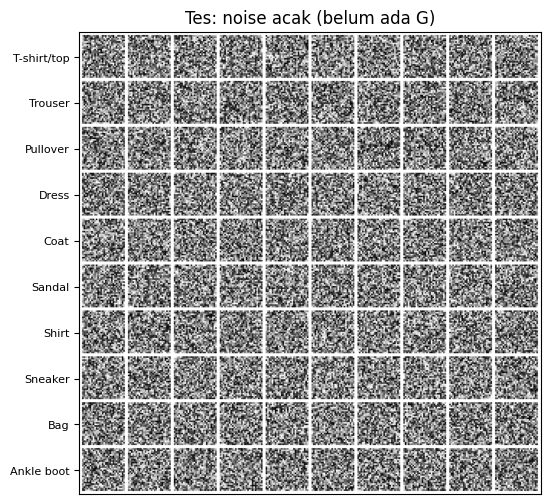

TES 1.2 LULUS


In [8]:
# --- Tes 1.2a: denormalize ---
t = torch.tensor([-1.0, 0.0, 1.0, -3.0, 3.0])
assert torch.allclose(denormalize(t), torch.tensor([0.0, 0.5, 1.0, 0.0, 1.0])), denormalize(t)
x01 = torch.rand(1000)                                     # "gambar asli" di [0, 1]
roundtrip = denormalize((x01 - CFG.norm_mean) / CFG.norm_std)   # Normalize lalu denormalize
assert torch.allclose(roundtrip, x01, atol=1e-6), "denormalize harus membalik Normalize"

# --- Tes 1.2b: fixed noise ---
z, y = make_fixed_noise()
assert z.shape == (100, CFG.z_dim) and y.shape == (100,), (z.shape, y.shape)
assert y.dtype == torch.long
assert (y[:10] == 0).all() and (y[10:20] == 1).all() and (y[-10:] == 9).all(), "baris ke-i harus kelas ke-i"
assert sorted(y.unique().tolist()) == list(range(10))
z_again, y_again = make_fixed_noise()
assert torch.equal(z, z_again) and torch.equal(y, y_again), "noise tetap harus identik tiap dipanggil"
set_seed(1); za, _ = make_fixed_noise()
set_seed(2); zb, _ = make_fixed_noise()
assert torch.equal(za, zb), "noise tetap tidak boleh bergantung pada seed global"
set_seed(CFG.seed)

# --- Tes 1.2c: simpan grid (ke folder sementara, tidak mengotori Drive) ---
with tempfile.TemporaryDirectory() as tmp:
    fake = torch.rand(100, 1, 28, 28, device=DEVICE) * 2 - 1        # seolah keluaran G, di [-1, 1]
    path = os.path.join(tmp, "sub", "grid_test.png")                # "sub" belum ada: harus dibuat otomatis
    grid = save_image_grid(fake, path)
    assert os.path.exists(path), "file PNG tidak terbentuk"
    assert Image.open(path).size == (302, 302), Image.open(path).size   # 10 * (28 + 2) + 2
assert grid.shape == (3, 302, 302), grid.shape

# --- Tes 1.2d: tampilan (cek visual) ---
show_image_grid(grid, "Tes: noise acak (belum ada G)", row_labels=CLASS_NAMES)

print("TES 1.2 LULUS")

### 1.3 Folder keluaran dan Google Drive

Runtime Colab gratis bisa terputus atau direset kapan saja, dan disk Colab ikut terhapus. Checkpoint, grid sampel, dan log yang hanya ada di disk Colab akan hilang. Karena itu keluaran disimpan ke **Google Drive**.

`setup_output_dirs(cfg)` memutuskan lokasinya:

- Di Colab dan `use_drive=True`: mount Google Drive lalu memakai `cfg.drive_root`.
- Jika mount gagal, atau notebook dijalankan di luar Colab: memakai folder lokal `cfg.local_root` dan mencetak **peringatan** (jangan lupa mengunduh hasilnya).
- Di kedua kasus, ia membuat subfolder `checkpoints/`, `samples/`, `logs/` dan mengisi `CFG.ckpt_dir`, `CFG.sample_dir`, `CFG.log_dir`. Inilah satu-satunya tempat di luar Bagian 0 yang boleh mengubah `CFG`.

**Saat menjalankan cell ini di Colab**, akan muncul jendela izin akses Google Drive. Pilih akun, lalu izinkan.

In [9]:
def setup_output_dirs(cfg: Config) -> None:
    """Tentukan lokasi keluaran (Drive atau lokal), buat foldernya, isi path di cfg."""
    in_colab = "google.colab" in sys.modules
    root = cfg.local_root                      # default aman: folder lokal

    if cfg.use_drive:
        if in_colab:
            try:
                from google.colab import drive
                drive.mount("/content/drive")  # memunculkan popup izin saat pertama kali
                root = cfg.drive_root
            except Exception as err:           # mount bisa gagal (izin ditolak, jaringan, dll.)
                print(f"PERINGATAN: gagal mount Google Drive ({err}).")
                print(f"Keluaran disimpan di {cfg.local_root} (HILANG jika runtime Colab direset).")
        else:
            print("Catatan: bukan Colab, Google Drive dilewati. Keluaran disimpan di folder lokal.")

    cfg.out_root = root
    cfg.ckpt_dir = os.path.join(root, "checkpoints")
    cfg.sample_dir = os.path.join(root, "samples")
    cfg.log_dir = os.path.join(root, "logs")
    for d in (cfg.ckpt_dir, cfg.sample_dir, cfg.log_dir):
        os.makedirs(d, exist_ok=True)          # exist_ok: aman dijalankan ulang


setup_output_dirs(CFG)
print("Folder keluaran :", os.path.abspath(CFG.out_root))
print("  checkpoints   :", CFG.ckpt_dir)
print("  samples       :", CFG.sample_dir)
print("  logs          :", CFG.log_dir)

Mounted at /content/drive
Folder keluaran : /content/drive/MyDrive/cgan_fashion_mnist
  checkpoints   : /content/drive/MyDrive/cgan_fashion_mnist/checkpoints
  samples       : /content/drive/MyDrive/cgan_fashion_mnist/samples
  logs          : /content/drive/MyDrive/cgan_fashion_mnist/logs


#### Tes 1.3: cara memeriksa folder keluaran

Tes memeriksa bahwa ketiga folder ada dan **benar-benar bisa ditulisi**: menulis satu file kecil, membacanya kembali, lalu menghapusnya. Folder yang ada tetapi tidak bisa ditulisi (misalnya izin Drive bermasalah) akan terdeteksi di sini, bukan di epoch ke-10 saat menyimpan checkpoint pertama.

**Hasil yang diharapkan:** `TES 1.3 LULUS`.

In [10]:
for d in (CFG.ckpt_dir, CFG.sample_dir, CFG.log_dir):
    assert os.path.isdir(d), f"folder tidak ada: {d}"
    probe = os.path.join(d, "_tulis_tes.txt")
    with open(probe, "w") as f:
        f.write("ok")
    with open(probe) as f:
        assert f.read() == "ok", f"gagal membaca kembali file di {d}"
    os.remove(probe)

print("TES 1.3 LULUS")

TES 1.3 LULUS


### 1.4 Simpan dan muat checkpoint

Checkpoint adalah satu file `.pt` berisi semua yang dibutuhkan untuk **melanjutkan training** atau **membuat gambar** nanti:

| Kunci | Isi | Kenapa perlu |
| --- | --- | --- |
| `epoch` | nomor epoch terakhir yang selesai | tahu harus lanjut dari mana |
| `G`, `D` | `state_dict` kedua jaringan | bobot hasil belajar |
| `opt_G`, `opt_D` | `state_dict` kedua optimizer | Adam menyimpan momentum dan variansi per bobot; kalau direset, training "dingin" lagi dan loss bisa melonjak |
| `config` | `asdict(CFG)` | mencatat hyperparameter yang dipakai run ini |
| `extra` | data bebas (mis. riwayat loss) | dipakai bagian training loop |

Keputusan desain:

- **Penulisan atomik.** File ditulis dulu ke `nama.pt.tmp`, lalu diganti nama dengan `os.replace` (operasi atomik). Jika Colab terputus di tengah penulisan, checkpoint lama tetap utuh dan tidak ada file setengah jadi.
- **`weights_only=True` saat memuat.** Hanya data tensor dan tipe dasar yang boleh dimuat, sehingga file `.pt` dari sumber tak dikenal tidak bisa menjalankan kode sembarang.
- **Nama file seragam** lewat `ckpt_path(epoch)`: `ckpt_epoch010.pt` (3 digit, supaya urutan alfabet = urutan epoch).
- **`latest_checkpoint()`** mencari checkpoint terbaru, dipakai untuk resume setelah runtime terputus.
- **`load_checkpoint`** memuat ke model/optimizer yang diberikan (boleh sebagian saja, mis. hanya G untuk generate) dan mengembalikan dict checkpoint.

In [11]:
def ckpt_path(epoch: int, directory: str = None) -> str:
    """Nama file checkpoint yang seragam: ckpt_epoch010.pt (3 digit agar urut alfabet = urut epoch)."""
    directory = CFG.ckpt_dir if directory is None else directory
    return os.path.join(directory, f"ckpt_epoch{epoch:03d}.pt")


def latest_checkpoint(directory: str = None):
    """Path checkpoint dengan epoch terbesar, atau None bila belum ada (untuk resume)."""
    directory = CFG.ckpt_dir if directory is None else directory
    if not os.path.isdir(directory):
        return None
    files = sorted(f for f in os.listdir(directory)
                   if f.startswith("ckpt_epoch") and f.endswith(".pt"))   # ".pt.tmp" otomatis terabaikan
    return os.path.join(directory, files[-1]) if files else None


def save_checkpoint(path: str, epoch: int, G: nn.Module, D: nn.Module,
                    opt_G, opt_D, extra: dict = None) -> None:
    """Simpan G, D, kedua optimizer, epoch, dan config dalam satu file."""
    ckpt = {
        "epoch": epoch,
        "G": G.state_dict(),
        "D": D.state_dict(),
        "opt_G": opt_G.state_dict(),     # momentum Adam ikut disimpan agar resume tidak "dingin"
        "opt_D": opt_D.state_dict(),
        "config": asdict(CFG),           # catatan hyperparameter run ini
        "extra": extra or {},            # mis. riwayat loss dari training loop
    }
    os.makedirs(os.path.dirname(path) or ".", exist_ok=True)
    tmp_path = path + ".tmp"
    torch.save(ckpt, tmp_path)           # tulis dulu ke file sementara...
    os.replace(tmp_path, path)           # ...lalu ganti nama (atomik): tidak ada file setengah jadi


def load_checkpoint(path: str, G: nn.Module = None, D: nn.Module = None,
                    opt_G=None, opt_D=None, map_location=None) -> dict:
    """Muat checkpoint ke objek yang diberikan (boleh sebagian saja). Mengembalikan dict checkpoint."""
    map_location = DEVICE if map_location is None else map_location
    # weights_only=True: hanya tensor dan tipe dasar yang boleh dimuat (lebih aman).
    ckpt = torch.load(path, map_location=map_location, weights_only=True)
    if G is not None:
        G.load_state_dict(ckpt["G"])
    if D is not None:
        D.load_state_dict(ckpt["D"])
    if opt_G is not None:
        opt_G.load_state_dict(ckpt["opt_G"])
    if opt_D is not None:
        opt_D.load_state_dict(ckpt["opt_D"])
    return ckpt

#### Tes 1.4: cara memeriksa checkpoint

Tes memakai dua jaringan mini (`nn.Linear`) agar cepat, dan folder sementara agar Drive tidak terkotori. Ia memeriksa siklus lengkap:

1. Simpan setelah satu langkah Adam (supaya state optimizer terisi), lalu muat ke model baru yang bobotnya berbeda.
2. Setelah dimuat: bobot G dan D **sama persis**, state Adam **sama persis**, `epoch` dan `config` dan `extra` kembali utuh.
3. Tidak ada file `.tmp` tersisa (penulisan atomik berhasil).
4. `latest_checkpoint` memilih epoch terbesar (bukan yang terakhir ditulis), dan mengembalikan `None` untuk folder kosong.
5. Memuat file yang tidak ada menghasilkan `FileNotFoundError`.

**Hasil yang diharapkan:** `TES 1.4 LULUS`.

In [12]:
def make_toy():
    """Model mini + optimizer yang sudah mengambil satu langkah (agar state Adam terisi)."""
    net = nn.Linear(4, 4).to(DEVICE)
    opt = torch.optim.Adam(net.parameters(), lr=CFG.lr_g, betas=(CFG.beta1, CFG.beta2))
    loss = net(torch.randn(8, 4, device=DEVICE)).pow(2).mean()
    opt.zero_grad(); loss.backward(); opt.step()
    return net, opt


def make_fresh():
    """Model mini + optimizer baru tanpa state (seperti saat resume di runtime baru)."""
    net = nn.Linear(4, 4).to(DEVICE)
    opt = torch.optim.Adam(net.parameters(), lr=CFG.lr_g, betas=(CFG.beta1, CFG.beta2))
    return net, opt


G1, optG1 = make_toy()
D1, optD1 = make_toy()
G2, optG2 = make_fresh()
D2, optD2 = make_fresh()
assert not torch.equal(G1.weight, G2.weight), "prasyarat tes: bobot awal harus berbeda"

with tempfile.TemporaryDirectory() as tmp:
    # --- simpan lalu muat ---
    p = ckpt_path(7, tmp)
    assert os.path.basename(p) == "ckpt_epoch007.pt"
    save_checkpoint(p, 7, G1, D1, optG1, optD1, extra={"loss_D": [1.4, 1.3]})
    assert os.path.exists(p), "checkpoint tidak terbentuk"
    assert not os.path.exists(p + ".tmp"), "file .tmp tidak boleh tersisa"

    ckpt = load_checkpoint(p, G2, D2, optG2, optD2)

    # bobot sama persis
    for src, dst in ((G1, G2), (D1, D2)):
        for k, v in src.state_dict().items():
            assert torch.equal(v, dst.state_dict()[k]), f"bobot {k} berbeda setelah dimuat"
    # state Adam sama persis
    for src, dst in ((optG1, optG2), (optD1, optD2)):
        s_src, s_dst = src.state_dict()["state"][0], dst.state_dict()["state"][0]
        assert torch.equal(s_src["exp_avg"], s_dst["exp_avg"]), "momentum Adam (exp_avg) berbeda"
        assert torch.equal(s_src["exp_avg_sq"], s_dst["exp_avg_sq"]), "variansi Adam (exp_avg_sq) berbeda"
    # metadata
    assert ckpt["epoch"] == 7
    assert ckpt["config"]["z_dim"] == CFG.z_dim and ckpt["config"]["seed"] == CFG.seed
    assert ckpt["extra"]["loss_D"] == [1.4, 1.3]

    # --- latest_checkpoint ---
    save_checkpoint(ckpt_path(10, tmp), 10, G1, D1, optG1, optD1)
    save_checkpoint(ckpt_path(3, tmp), 3, G1, D1, optG1, optD1)     # ditulis terakhir, tapi epoch kecil
    assert latest_checkpoint(tmp) == ckpt_path(10, tmp), "harus memilih epoch terbesar"
    with tempfile.TemporaryDirectory() as empty:
        assert latest_checkpoint(empty) is None, "folder kosong harus menghasilkan None"
    assert latest_checkpoint(os.path.join(tmp, "tidak_ada")) is None

    # --- file tidak ada ---
    try:
        load_checkpoint(os.path.join(tmp, "tidak_ada.pt"))
    except FileNotFoundError:
        pass
    else:
        raise AssertionError("memuat file yang tidak ada seharusnya FileNotFoundError")

print("TES 1.4 LULUS")

TES 1.4 LULUS


# Bagian 2: Generator

## Konsep: apa tugas Generator?

Generator (G) adalah "pemalsu". Ia menerima **noise acak** `z` (sumber variasi: satu `z` = satu gambar yang berbeda) dan **label kelas** `y` (perintah: "buatkan sepatu"), lalu menghasilkan gambar 28×28 yang diharapkan menipu Discriminator. Label mengendalikan **apa** yang digambar, noise mengendalikan **variasinya**.

Ide arsitekturnya: mulai dari vektor kecil, ubah menjadi "gambar benih" 7×7 dengan banyak channel, perbesar dua kali (7 → 14 → 28) sambil mengurangi jumlah channel, lalu peras menjadi 1 channel gambar. Semua ukuran diambil dari `CFG` (tidak ada angka ukuran baru di kode).

| # | Layer | Output (baseline) | Kenapa dipilih |
| --- | --- | --- | --- |
| 1 | `Embedding(num_classes, g_embed_dim)` pada `y` | [B, 50] | Mengubah label menjadi vektor yang **dipelajari**. Lebih kaya daripada one-hot 10 dimensi dan tidak tenggelam di antara noise |
| 2 | Concat(`z`, embedding) | [B, 150] | Cara memasukkan label paling sederhana dan mudah dijelaskan: kelas menjadi bagian dari "bahan baku" gambar |
| 3 | `Linear` → reshape → `BatchNorm2d` → `ReLU` | [B, 128, 7, 7] | Layer konvolusi butuh tata letak spasial, jadi vektor diproyeksikan menjadi peta fitur kecil. 7 dipilih karena 28 / 4 = 7: dua kali penggandaan tepat sampai 28 |
| 4 | `ConvTranspose2d` (k=4, s=2, p=1) → `BatchNorm2d` → `ReLU` | [B, 64, 14, 14] | Memperbesar resolusi 2× dengan filter yang dipelajari |
| 5 | `ConvTranspose2d` (k=4, s=2, p=1) → `BatchNorm2d` → `ReLU` | [B, 32, 28, 28] | Tahap penggandaan kedua, sampai ukuran gambar |
| 6 | `Conv2d` 3×3 → `Tanh` | [B, 1, 28, 28] | Memetakan 32 channel menjadi 1 channel gambar; `Tanh` menghasilkan rentang [-1, 1] |

**Keputusan desain yang perlu bisa dijelaskan**

- **ConvTranspose2d dengan k=4, s=2, p=1.** Rumus ukuran keluarannya `(n − 1)·2 − 2·1 + 4 = 2n`, jadi persis menggandakan sisi. Kernel 4 habis dibagi stride 2, sehingga pola kotak-kotak (*checkerboard*) lebih ringan daripada kernel 3.
- **Channel berkurang saat resolusi naik** (128 → 64 → 32). Jumlah angka per layer naik terkendali (6.272 → 12.544 → 25.088) dan model tetap ringan.
- **Layer keluaran tanpa BatchNorm dan ReLU.** BatchNorm akan menormalkan skala keluaran, padahal kita ingin G bebas mengatur intensitas piksel; `Tanh` langsung memberi rentang [-1, 1] yang sama dengan data.
- **`bias=False` sebelum BatchNorm**, karena BatchNorm membatalkan bias (ia mengurangi rata-rata per channel).
- **`weights_init` dipanggil di dalam konstruktor**, jadi tidak mungkin ada G yang lupa diinisialisasi.
- **Parameter ±1,1 juta, dan ±85% ada di layer `Linear`** (150 × 6.272 = 940.800). Proyeksi ke peta fitur 7×7 adalah bagian terbesar G.
- **Pemeriksaan input** di `forward` (bentuk `z`, bentuk dan tipe `y`) dengan pesan jelas, karena salah bentuk atau salah tipe label adalah sumber bug yang paling sering muncul saat G dan training loop disambungkan.
- **Batch berisi 1 sampel aman**: `BatchNorm2d` menghitung statistik per channel dari 7×7 = 49 nilai spasial (bukan dari batch saja), jadi tidak error di mode train maupun eval.

**Catatan penting tentang mode `eval`:** BatchNorm di mode `eval` memakai statistik berjalan (*running mean/var*) yang masih di nilai awal (0 dan 1) pada G yang belum dilatih. Akibatnya G yang belum dilatih menghasilkan gambar hampir **abu-abu rata** di mode `eval`, sedangkan di mode `train` tampak tekstur derau. Ini normal dan akan hilang setelah statistik berjalan terisi selama training. Tes 2.5 menampilkan keduanya supaya tim tidak kaget.

### 2.1 Kelas `Generator`

Kode di bawah mengikuti tabel di atas. Ukuran layer dibaca dari `CFG` (`z_dim`, `g_embed_dim`, `g_channels`, `g_init_size`, `num_classes`, `img_channels`). Konstanta arsitektur (kernel 4, stride 2, padding 1, dan kernel 3 di layer keluaran) adalah **pilihan desain**, bukan ukuran data, sehingga ditulis langsung dengan komentar alasannya. Konstruktor juga memeriksa bahwa `g_init_size × 2^(jumlah tahap)` sama dengan `img_size`, jadi config yang tidak konsisten ditolak dengan pesan yang jelas.

In [13]:
class Generator(nn.Module):
    """Generator cGAN: (noise z, label y) -> gambar [B, 1, 28, 28] di rentang [-1, 1].

    Alur (ukuran dari CFG, contoh angka untuk konfigurasi baseline):
      embed(y)                  [B, 50]
      concat(z, embed)          [B, 150]
      Linear + reshape          [B, 128, 7, 7]    -> BatchNorm2d -> ReLU
      ConvTranspose2d (x2 res)  [B,  64, 14, 14]  -> BatchNorm2d -> ReLU
      ConvTranspose2d (x2 res)  [B,  32, 28, 28]  -> BatchNorm2d -> ReLU
      Conv2d 3x3 + Tanh         [B,   1, 28, 28]
    """

    def __init__(self):
        super().__init__()
        chs = CFG.g_channels                    # (128, 64, 32)
        n_up = len(chs) - 1                     # jumlah tahap penggandaan resolusi (2)
        # Pagar pengaman: resolusi awal dikali 2 tiap tahap harus tepat sama dengan ukuran gambar.
        if CFG.g_init_size * 2 ** n_up != CFG.img_size:
            raise ValueError(
                f"g_init_size ({CFG.g_init_size}) x 2^{n_up} = {CFG.g_init_size * 2 ** n_up}, "
                f"tidak sama dengan img_size ({CFG.img_size}). Periksa CFG.g_channels dan CFG.g_init_size.")

        self.init_ch = chs[0]
        self.init_size = CFG.g_init_size

        # 1) Label -> vektor yang dipelajari (bukan one-hot), lalu digabung dengan noise.
        self.embed = nn.Embedding(CFG.num_classes, CFG.g_embed_dim)

        # 2) Proyeksi: vektor [z ; embed] -> "gambar benih" kecil 128 kanal x 7 x 7.
        #    bias=False karena BatchNorm sesudahnya membatalkan bias.
        self.project = nn.Linear(CFG.z_dim + CFG.g_embed_dim,
                                 self.init_ch * self.init_size ** 2, bias=False)
        self.bn0 = nn.BatchNorm2d(self.init_ch)
        self.act0 = nn.ReLU()

        # 3) Tahap penggandaan resolusi: 7 -> 14 -> 28.
        #    kernel=4, stride=2, padding=1 menggandakan sisi persis: (n-1)*2 - 2*1 + 4 = 2n.
        #    Kernel 4 habis dibagi stride 2, sehingga pola kotak-kotak (checkerboard) lebih ringan.
        ups = []
        for c_in, c_out in zip(chs[:-1], chs[1:]):            # (128->64), (64->32)
            ups += [nn.ConvTranspose2d(c_in, c_out, kernel_size=4, stride=2, padding=1, bias=False),
                    nn.BatchNorm2d(c_out),
                    nn.ReLU()]
        self.up = nn.Sequential(*ups)

        # 4) Layer keluaran: Conv 3x3 menghaluskan dan memetakan 32 kanal -> 1 kanal gambar.
        #    Tanpa BatchNorm/ReLU: Tanh langsung memberi rentang [-1, 1] sesuai normalisasi data.
        self.to_img = nn.Sequential(
            nn.Conv2d(chs[-1], CFG.img_channels, kernel_size=3, stride=1, padding=1),
            nn.Tanh(),
        )

        # Inisialisasi dilakukan di dalam konstruktor agar tidak mungkin terlupa.
        self.apply(weights_init)

    def forward(self, z: torch.Tensor, y: torch.Tensor) -> torch.Tensor:
        # Pemeriksaan input dengan pesan jelas (error bentuk/tipe adalah sumber bug yang paling sering).
        if z.dim() != 2 or z.size(1) != CFG.z_dim:
            raise ValueError(f"z harus berbentuk [B, {CFG.z_dim}], diterima {tuple(z.shape)}")
        if y.dim() != 1 or y.size(0) != z.size(0):
            raise ValueError(f"y harus berbentuk [{z.size(0)}] (satu label per noise), diterima {tuple(y.shape)}")
        if y.dtype != torch.long:
            raise TypeError(f"y harus bertipe torch.long (indeks kelas), diterima {y.dtype}")
        # Catatan: label di luar 0..num_classes-1 menyebabkan IndexError di CPU
        # dan "device-side assert" di GPU. Pemeriksaan rentang sengaja tidak ditambahkan
        # di sini karena memaksa sinkronisasi GPU pada setiap iterasi.

        e = self.embed(y)                          # [B, 50]
        h = torch.cat([z, e], dim=1)               # [B, 150]
        h = self.project(h)                        # [B, 6272]
        h = h.view(h.size(0), self.init_ch, self.init_size, self.init_size)   # [B, 128, 7, 7]
        h = self.act0(self.bn0(h))
        h = self.up(h)                             # [B, 32, 28, 28]
        return self.to_img(h)                      # [B, 1, 28, 28], rentang [-1, 1]

### 2.2 Membuat G (belum dilatih)

`set_seed` dipanggil sebelum membuat G supaya bobot awalnya sama di setiap run. `print(G)` menampilkan urutan layer untuk dicocokkan dengan tabel di atas.

In [14]:
set_seed(CFG.seed)                 # bobot awal G sama di setiap run
G = Generator().to(DEVICE)         # weights_init sudah dipanggil di dalam konstruktor
print(G)
print(f"\nJumlah parameter: {sum(p.numel() for p in G.parameters()):,}")

Generator(
  (embed): Embedding(10, 50)
  (project): Linear(in_features=150, out_features=6272, bias=False)
  (bn0): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (act0): ReLU()
  (up): Sequential(
    (0): ConvTranspose2d(128, 64, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): ConvTranspose2d(64, 32, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (4): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (5): ReLU()
  )
  (to_img): Sequential(
    (0): Conv2d(32, 1, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): Tanh()
  )
)

Jumlah parameter: 1,105,877


### Tes 2: cara memeriksa Generator

Enam tes, masing-masing di cell sendiri supaya error mudah dilokalisasi. Tes memakai mode `eval` + `torch.no_grad()` (kecuali bila disebut lain) dan **salinan** G (`copy.deepcopy`) untuk tes mode `train`/gradien, sehingga G asli tidak berubah. Tes terakhir memastikan hal itu.

| Tes | Yang diperiksa |
| --- | --- |
| 2.1 (a) | bentuk keluaran [B,1,28,28], rentang [-1,1], dan bentuk keluaran tiap layer sesuai tabel |
| 2.2 (b) | jumlah parameter ±1,1 juta |
| 2.3 (c) | `z` sama dengan label berbeda menghasilkan gambar berbeda |
| 2.4 (d) | batch berisi 1 sampel tetap berjalan di mode eval |
| 2.5 (e) | grid noise tetap dari G yang belum dilatih |
| 2.6 | tambahan: gradien sampai ke semua parameter, validasi input, inisialisasi `weights_init`, dan G tidak berubah oleh tes |

#### Tes 2.1 (a): bentuk dan rentang

Selain bentuk akhir [B, 1, 28, 28] dan rentang [-1, 1], tes memasang *hook* di setiap layer terdalam untuk mencatat bentuk keluarannya, lalu mencocokkan dengan tabel konsep (dihitung dari `CFG`, bukan angka tetap). Pengaturan layer (kernel, stride, padding) juga dicocokkan dengan cetak biru. Tabel bentuk per layer dicetak, berguna untuk presentasi.

**Hasil yang diharapkan:** tabel bentuk per layer, lalu `TES 2.1 LULUS`.

In [15]:
import copy   # dipakai tes yang berjalan di mode train / menghitung gradien: G asli tidak boleh tersentuh

# Foto kondisi G sebelum tes; Tes 2.6 memastikan semua tes tidak mengubah G.
G_state_before = {k: v.detach().clone() for k, v in G.state_dict().items()}

B = 16
set_seed(CFG.seed)
z = torch.randn(B, CFG.z_dim, device=DEVICE)
y = torch.randint(0, CFG.num_classes, (B,), device=DEVICE)

# Pasang "pengintai" (forward hook) di tiap layer terdalam untuk mencatat bentuk keluarannya.
shapes = {}
hooks = [m.register_forward_hook(lambda m, inp, o, name=n: shapes.__setitem__(name, tuple(o.shape)))
         for n, m in G.named_modules() if len(list(m.children())) == 0]
G.eval()
with torch.no_grad():
    out = G(z, y)
for h in hooks:
    h.remove()

# Bentuk yang diharapkan, dihitung dari CFG (bukan angka tetap).
chs, s = CFG.g_channels, CFG.g_init_size
expected = {
    "embed":    (B, CFG.g_embed_dim),
    "project":  (B, chs[0] * s * s),
    "bn0":      (B, chs[0], s, s),
    "to_img.0": (B, CFG.img_channels, CFG.img_size, CFG.img_size),
}
for k in range(len(chs) - 1):                    # tahap penggandaan ke-k: ConvTranspose ada di indeks up.(3k)
    side = s * 2 ** (k + 1)
    expected[f"up.{3 * k}"] = (B, chs[k + 1], side, side)

print(f"{'layer':10s} bentuk keluaran")
for name, shp in shapes.items():
    print(f"{name:10s} {shp}" + ("   <- dicek" if name in expected else ""))
for name, shp in expected.items():
    assert shapes[name] == shp, f"layer {name}: bentuk {shapes[name]}, seharusnya {shp}"

# Pengaturan layer sesuai cetak biru: ConvTranspose2d k=4, s=2, p=1; Conv2d keluaran k=3, s=1, p=1.
for k in range(len(chs) - 1):
    ct = G.up[3 * k]
    assert (ct.kernel_size, ct.stride, ct.padding) == ((4, 4), (2, 2), (1, 1)), f"up.{3 * k}: pengaturan ConvTranspose2d salah"
last = G.to_img[0]
assert (last.kernel_size, last.stride, last.padding) == ((3, 3), (1, 1), (1, 1)), "Conv2d keluaran harus k=3, s=1, p=1"

# Bentuk akhir dan rentang nilai
assert out.shape == (B, CFG.img_channels, CFG.img_size, CFG.img_size), out.shape
assert out.dtype == torch.float32
assert torch.isfinite(out).all(), "ada NaN/Inf di keluaran G"
assert out.min() >= -1.0 and out.max() <= 1.0, f"keluaran di luar [-1, 1]: [{out.min():.3f}, {out.max():.3f}]"

# Hal yang sama di mode train (pada salinan; BatchNorm memakai statistik batch)
G_train_copy = copy.deepcopy(G).train()
with torch.no_grad():
    out_train = G_train_copy(z, y)
assert out_train.shape == out.shape
assert torch.isfinite(out_train).all() and out_train.min() >= -1.0 and out_train.max() <= 1.0

print("TES 2.1 LULUS")

layer      bentuk keluaran
embed      (16, 50)   <- dicek
project    (16, 6272)   <- dicek
bn0        (16, 128, 7, 7)   <- dicek
act0       (16, 128, 7, 7)
up.0       (16, 64, 14, 14)   <- dicek
up.1       (16, 64, 14, 14)
up.2       (16, 64, 14, 14)
up.3       (16, 32, 28, 28)   <- dicek
up.4       (16, 32, 28, 28)
up.5       (16, 32, 28, 28)
to_img.0   (16, 1, 28, 28)   <- dicek
to_img.1   (16, 1, 28, 28)
TES 2.1 LULUS


#### Tes 2.2 (b): jumlah parameter

Menghitung semua parameter, mencetak rinciannya per bagian, dan memeriksa bahwa totalnya berada dalam ±5% dari 1,1 juta (cetak biru bagian 2). Semua parameter juga harus *trainable*.

**Hasil yang diharapkan:** total 1.105.877 parameter (angka ini bisa dicocokkan dengan hitungan tangan di tabel konsep), lalu `TES 2.2 LULUS`.

In [16]:
n_params = sum(p.numel() for p in G.parameters())
print(f"{'bagian':10s} {'parameter':>10s}")
for name, mod in G.named_children():
    print(f"{name:10s} {sum(p.numel() for p in mod.parameters()):>10,}")
print(f"{'TOTAL':10s} {n_params:>10,}")

target = 1_100_000                                  # target cetak biru: ±1,1 juta
assert abs(n_params - target) / target < 0.05, f"{n_params:,} parameter, di luar ±5% dari {target:,}"
assert all(p.requires_grad for p in G.parameters()), "ada parameter yang tidak trainable"
share = G.project.weight.numel() / n_params
print(f"Layer Linear (project) menyumbang {share:.0%} dari total parameter.")

print("TES 2.2 LULUS")

bagian      parameter
embed             500
project       940,800
bn0               256
act0                0
up            164,032
to_img            289
TOTAL       1,105,877
Layer Linear (project) menyumbang 85% dari total parameter.
TES 2.2 LULUS


#### Tes 2.3 (c): label benar-benar berpengaruh

Satu vektor `z` yang sama diberi 10 label berbeda. Yang diperiksa:

1. **Deterministik:** input yang sama di mode eval menghasilkan keluaran yang sama persis.
2. **Label mengubah gambar:** selisih rata-rata antar-gambar (rata-rata selisih absolut per piksel) untuk setiap pasangan label harus jelas di atas derau numerik.
3. **Pengaruh label sebanding dengan pengaruh `z`:** pada G yang belum dilatih, embedding label dan `z` sama-sama N(0, 1), jadi pengaruhnya harus sepadan. Rasio selisih-antar-label terhadap selisih-antar-`z` yang jauh di bawah 0,1 menandakan jalur label bermasalah (misalnya embedding salah skala atau tidak masuk ke `concat`).

**Hasil yang diharapkan:** angka selisih tercetak, lalu `TES 2.3 LULUS`. Selisih absolutnya kecil (orde 1e-3) karena G belum dilatih; yang penting adalah rasionya.

In [17]:
def pairwise_abs_diff(imgs: torch.Tensor) -> torch.Tensor:
    """Selisih absolut rata-rata per piksel untuk setiap pasangan gambar (segitiga atas)."""
    flat = imgs.flatten(1)
    d = torch.cdist(flat, flat, p=1) / flat.size(1)          # jarak L1 dibagi jumlah piksel
    n = imgs.size(0)
    mask = torch.triu(torch.ones(n, n, dtype=torch.bool, device=imgs.device), diagonal=1)
    return d[mask]


set_seed(CFG.seed)
n = CFG.num_classes
z_same = torch.randn(1, CFG.z_dim, device=DEVICE).repeat(n, 1)      # SATU z, disalin 10 kali
labels = torch.arange(n, device=DEVICE)                             # label 0..9
z_many = torch.randn(n, CFG.z_dim, device=DEVICE)                   # 10 z berbeda
label_zero = torch.zeros(n, dtype=torch.long, device=DEVICE)        # label sama untuk semua

G.eval()
with torch.no_grad():
    out_a = G(z_same, labels)
    out_b = G(z_same, labels)
    out_z = G(z_many, label_zero)

assert torch.equal(out_a, out_b), "input yang sama di mode eval harus memberi keluaran yang sama persis"

d_label = pairwise_abs_diff(out_a)      # z sama, label berbeda
d_z = pairwise_abs_diff(out_z)          # label sama, z berbeda
ratio = (d_label.min() / d_z.mean()).item()
print(f"selisih antar-label  : min {d_label.min():.5f}  rata-rata {d_label.mean():.5f}")
print(f"selisih antar-z      : min {d_z.min():.5f}  rata-rata {d_z.mean():.5f}")
print(f"rasio min(label) / rata-rata(z) = {ratio:.2f}")

assert d_label.min() > 1e-5, "z sama dengan label berbeda menghasilkan gambar (hampir) identik: label tidak berpengaruh"
assert ratio > 0.1, f"pengaruh label jauh lebih kecil daripada pengaruh z (rasio {ratio:.3f}): periksa jalur label"

print("TES 2.3 LULUS")

selisih antar-label  : min 0.00145  rata-rata 0.00172
selisih antar-z      : min 0.00202  rata-rata 0.00230
rasio min(label) / rata-rata(z) = 0.63
TES 2.3 LULUS


#### Tes 2.4 (d): batch berisi 1 sampel di mode eval

Saat generate gambar, sering hanya satu sampel yang dibuat. Tes memeriksa:

1. Satu sampel (untuk label pertama dan terakhir) menghasilkan [1, 1, 28, 28] dan tetap di rentang [-1, 1].
2. Di mode `eval`, hasil satu sampel **sama** dengan hasil sampel yang sama saat berada di dalam batch (BatchNorm memakai statistik berjalan, bukan statistik batch, jadi sampel tidak saling memengaruhi).
3. Bonus: di mode `train` (pada salinan) batch 1 juga tidak error, karena `BatchNorm2d` menghitung statistik dari 49 nilai spasial per channel.

**Hasil yang diharapkan:** `TES 2.4 LULUS`.

In [18]:
set_seed(CFG.seed)
z5 = torch.randn(5, CFG.z_dim, device=DEVICE)
y5 = torch.randint(0, CFG.num_classes, (5,), device=DEVICE)

G.eval()
with torch.no_grad():
    # 1) batch 1 untuk label pertama dan terakhir
    for label in (0, CFG.num_classes - 1):
        one = G(torch.randn(1, CFG.z_dim, device=DEVICE), torch.tensor([label], device=DEVICE))
        assert one.shape == (1, CFG.img_channels, CFG.img_size, CFG.img_size), one.shape
        assert torch.isfinite(one).all() and one.min() >= -1.0 and one.max() <= 1.0

    # 2) di mode eval, hasil sebuah sampel tidak bergantung pada sampel lain dalam batch
    batched = G(z5, y5)
    for i in range(5):
        single = G(z5[i:i + 1], y5[i:i + 1])
        assert torch.allclose(single, batched[i:i + 1], atol=1e-6), f"sampel {i}: batch 1 beda dengan di dalam batch"

# 3) bonus: mode train + batch 1 pada salinan
G_copy = copy.deepcopy(G).train()
with torch.no_grad():
    out1 = G_copy(z5[:1], y5[:1])
assert out1.shape == (1, CFG.img_channels, CFG.img_size, CFG.img_size)

print("TES 2.4 LULUS")

TES 2.4 LULUS


#### Tes 2.5 (e): grid noise tetap dari G yang belum dilatih

Memakai `make_fixed_noise()` dan `save_image_grid` dari Bagian 1: 10 baris (kelas) × 10 kolom (sampel). Ini adalah "epoch 0" yang nanti dibandingkan dengan grid hasil training. File ditulis ke folder sementara, jadi Drive tidak terkotori.

Dua grid ditampilkan:

- **Mode eval**: cara grid disimpan saat training. Pada G yang belum dilatih tampak **abu-abu rata** (statistik BatchNorm belum terisi).
- **Mode train** (pada salinan): tampak **tekstur derau abu-abu**.

Keduanya **belum** menyerupai pakaian, dan itu benar karena G belum dilatih. Yang diperiksa tes: bentuk [100, 1, 28, 28], semua nilai sah, file PNG 302×302 terbentuk, dan di mode train gambar memang bervariasi.

**Hasil yang diharapkan:** dua gambar grid, lalu `TES 2.5 LULUS`.

std piksel  eval: 0.0027   train: 0.1707


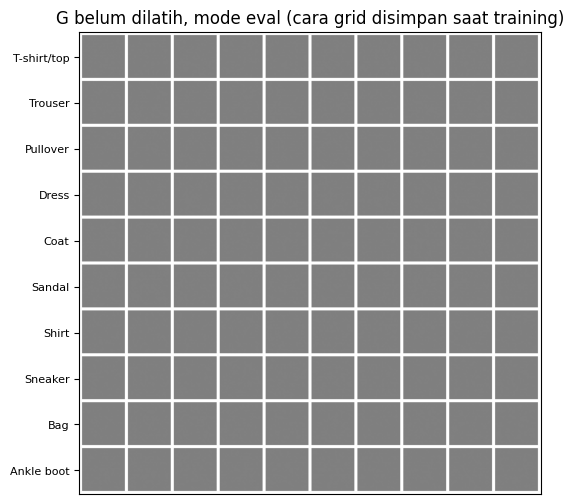

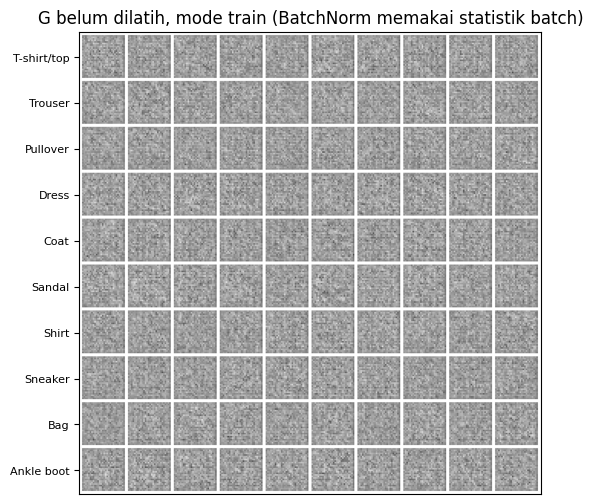

TES 2.5 LULUS


In [19]:
z_fixed, y_fixed = make_fixed_noise()                     # [100, 100] dan [100], baris ke-i = kelas ke-i

G.eval()
with torch.no_grad():
    imgs_eval = G(z_fixed, y_fixed)
G_train_copy = copy.deepcopy(G).train()                   # salinan: statistik BatchNorm G asli tidak tersentuh
with torch.no_grad():
    imgs_train = G_train_copy(z_fixed, y_fixed)

n_fixed = CFG.num_classes * CFG.n_per_class_grid
for imgs in (imgs_eval, imgs_train):
    assert imgs.shape == (n_fixed, CFG.img_channels, CFG.img_size, CFG.img_size), imgs.shape
    assert torch.isfinite(imgs).all() and imgs.min() >= -1.0 and imgs.max() <= 1.0
print(f"std piksel  eval: {imgs_eval.std():.4f}   train: {imgs_train.std():.4f}")
assert imgs_train.std() > 0.05, "di mode train gambar seharusnya bervariasi (bukan konstan)"

with tempfile.TemporaryDirectory() as tmp:
    grid_eval = save_image_grid(imgs_eval, os.path.join(tmp, "g_untrained_eval.png"))
    grid_train = save_image_grid(imgs_train, os.path.join(tmp, "g_untrained_train.png"))
    assert Image.open(os.path.join(tmp, "g_untrained_eval.png")).size == (302, 302)

show_image_grid(grid_eval, "G belum dilatih, mode eval (cara grid disimpan saat training)", row_labels=CLASS_NAMES)
show_image_grid(grid_train, "G belum dilatih, mode train (BatchNorm memakai statistik batch)", row_labels=CLASS_NAMES)

print("TES 2.5 LULUS")

#### Tes 2.6: tambahan (gradien, validasi input, inisialisasi, G tidak berubah)

Empat pemeriksaan di luar daftar utama, karena menangkap bug yang paling sering muncul saat G disambungkan ke training loop:

1. **Gradien sampai ke semua parameter** (pada salinan G). Parameter tanpa gradien berarti ada bagian G yang terputus dari loss, termasuk embedding label.
2. **Validasi input:** `z` salah bentuk, `y` salah panjang, dan `y` bukan `long` harus ditolak dengan `ValueError`/`TypeError`.
3. **Inisialisasi dari `weights_init`:** bobot Conv/ConvTranspose/Linear berstd ≈ `CFG.init_std`, bias nol, dan bobot BatchNorm berpusat di 1. Toleransi mengikuti jumlah bobot per layer; init default PyTorch akan terdeteksi sebagai salah.
4. **G asli tidak berubah** oleh seluruh tes di atas (bobot dan buffer BatchNorm sama persis dengan foto di Tes 2.1).

**Hasil yang diharapkan:** `TES 2.6 LULUS`.

In [20]:
# --- 1) gradien sampai ke semua parameter (pada salinan G) ---
G_grad = copy.deepcopy(G).train()
z8 = torch.randn(8, CFG.z_dim, device=DEVICE)
y8 = torch.randint(0, CFG.num_classes, (8,), device=DEVICE)
G_grad(z8, y8).mean().backward()
bad = [n for n, p in G_grad.named_parameters() if p.grad is None or not torch.isfinite(p.grad).all()]
assert not bad, f"parameter tanpa gradien (atau gradien tidak sah): {bad}"
assert G_grad.embed.weight.grad.abs().sum() > 0, "gradien embedding label nol: jalur label terputus"

# --- 2) validasi input ---
def expect_error(exc_type, fn, what):
    try:
        fn()
    except exc_type:
        return
    raise AssertionError(f"{what}: seharusnya memunculkan {exc_type.__name__}")

y4 = torch.zeros(4, dtype=torch.long, device=DEVICE)
expect_error(ValueError, lambda: G(torch.randn(4, CFG.z_dim + 1, device=DEVICE), y4), "z salah dimensi")
expect_error(ValueError, lambda: G(torch.randn(4, CFG.z_dim, device=DEVICE), y4[:3]), "y salah panjang")
expect_error(TypeError, lambda: G(torch.randn(4, CFG.z_dim, device=DEVICE), y4.float()), "y bukan long")

# --- 3) inisialisasi dari weights_init (G belum dilatih, jadi bobotnya masih bobot awal) ---
for name, mod in G.named_modules():
    if isinstance(mod, (nn.Conv2d, nn.ConvTranspose2d, nn.Linear)):
        n_w = mod.weight.numel()
        tol_std = 5 * CFG.init_std / (2 * n_w) ** 0.5      # toleransi = 5 galat baku sampling
        tol_mean = 5 * CFG.init_std / n_w ** 0.5
        assert abs(mod.weight.std().item() - CFG.init_std) < tol_std, \
            f"{name}: std bobot {mod.weight.std().item():.4f}, seharusnya ~{CFG.init_std} (weights_init tidak terpanggil?)"
        assert abs(mod.weight.mean().item()) < tol_mean, f"{name}: mean bobot harus ~0"
        if mod.bias is not None:
            assert torch.count_nonzero(mod.bias) == 0, f"{name}: bias harus 0"
    elif isinstance(mod, nn.BatchNorm2d):
        assert abs(mod.weight.mean().item() - 1.0) < 0.02, f"{name}: weight BatchNorm harus berpusat di ~1"
        assert torch.count_nonzero(mod.bias) == 0, f"{name}: bias BatchNorm harus 0"

# --- 4) G asli tidak berubah oleh tes-tes sebelumnya ---
for k, v in G.state_dict().items():
    assert torch.equal(v, G_state_before[k]), f"tes mengubah G: {k}"

print("TES 2.6 LULUS")

TES 2.6 LULUS


# Serah-terima ke bagian berikutnya

Yang sudah tersedia (jangan didefinisikan ulang):

| Nama | Asal | Fungsi |
| --- | --- | --- |
| `CFG`, `DEVICE`, `CLASS_NAMES`, `set_seed` | Bagian 0 | config, device, nama kelas, kunci keacakan |
| `weights_init`, `denormalize`, `make_fixed_noise`, `save_image_grid`, `show_image_grid` | 1.1, 1.2 | init bobot dan grid sampel |
| `setup_output_dirs` (sudah dipanggil), `ckpt_path`, `save_checkpoint`, `load_checkpoint`, `latest_checkpoint` | 1.3, 1.4 | folder keluaran, simpan/muat/resume |
| `Generator` | 2.1 | `G(z [B, z_dim], y [B] bertipe long)` → gambar [B, 1, 28, 28] di [-1, 1] |

Catatan untuk training loop dan evaluasi:

- Buat G untuk training dengan `set_seed(CFG.seed)` lalu `Generator().to(DEVICE)`. Variabel `G` di Bagian 2.2 dipakai untuk tes (sudah dibuktikan tidak berubah oleh tes), tetapi membuat ulang menjaga hasil yang reproducible.
- Panggil `G.train()` saat training dan `G.eval()` + `torch.no_grad()` saat menyimpan grid atau menghitung metrik. Selama statistik BatchNorm belum terisi (epoch awal), grid mode eval bisa tampak datar; itu normal.
- Label untuk G harus `torch.long` dan satu device dengan G, dengan rentang 0 sampai `CFG.num_classes - 1`.
- Contoh grid per epoch: `z_fixed, y_fixed = make_fixed_noise()`, lalu `save_image_grid(G(z_fixed, y_fixed), os.path.join(CFG.sample_dir, f"epoch_{epoch:03d}.png"))`.